<a href="https://colab.research.google.com/github/saichandanss2190/ITA0315-Mobile-Computing/blob/main/MC_Exp_21.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Scheduler | U    1 U    2 U    3 U    4 U    5 U    6 | Total | Jain
        RR |  1.235  0.996  0.703  0.479  0.297  0.152 |  3.861 | 0.741
     MaxCI |  6.061  1.630  0.199  0.015  0.002  0.000 |  7.906 | 0.264
        PF |  1.689  1.375  1.038  0.741  0.476  0.257 |  5.576 | 0.778


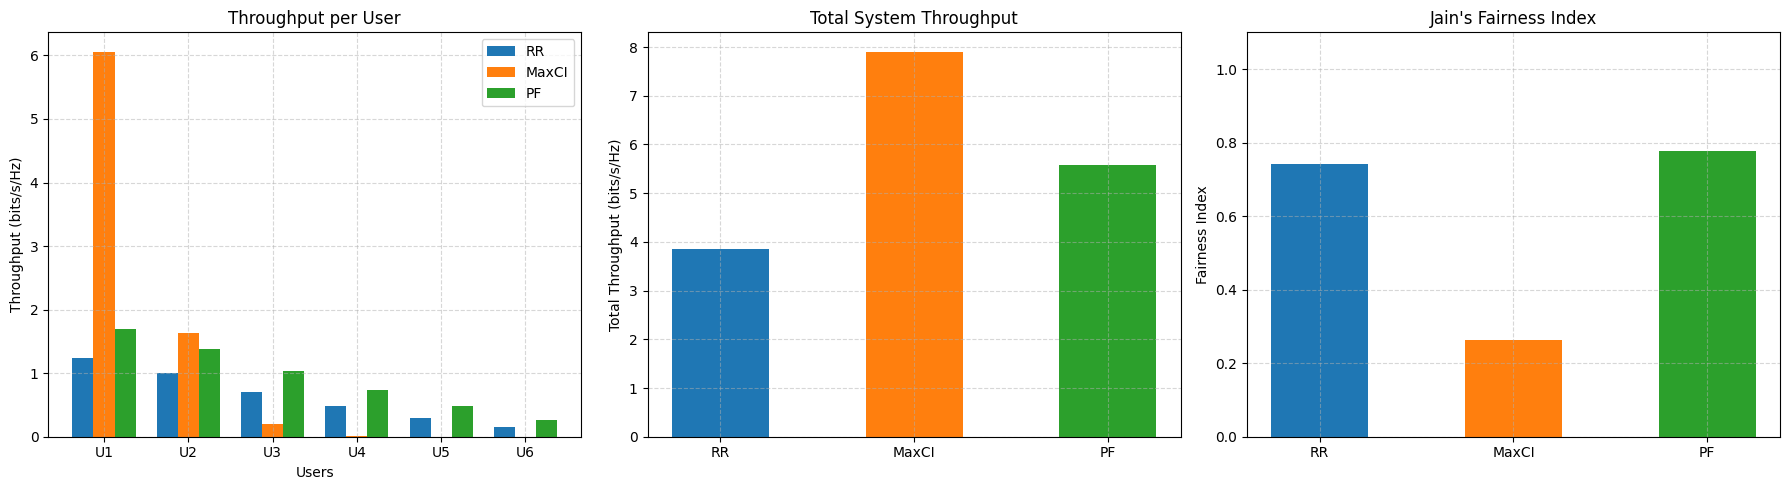

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
U, TTI, RB = 6, 2000, 1
mean_snr_db = np.array([25, 20, 15, 10, 5, 0]) # users near -> far
mean_snr = 10**(mean_snr_db/10)

# Rayleigh fading -> exponential power gain, rate by Shannon (bits/s/Hz)
rate = np.log2(1 + mean_snr * rng.exponential(1.0, (TTI, U)))

def jain(x):
    return x.sum()**2 / (len(x) * (x**2).sum())

def simulate(policy):
    served = np.zeros(U)
    avg = np.ones(U)
    for t in range(TTI):
        if policy == 'RR':
            u = t % U
        elif policy == 'MaxCI':
            u = np.argmax(rate[t])
        else:
            u = np.argmax(rate[t] / avg) # proportional fair
        served[u] += rate[t, u]
        inst = np.zeros(U)
        inst[u] = rate[t, u]
        avg = 0.99*avg + 0.01*inst
    return served / TTI

results = {}
print(f"{'Scheduler':>10} | " + " ".join(f"U{i+1:>5}" for i in range(U)) + " | Total | Jain")
for p in ('RR', 'MaxCI', 'PF'):
    th = simulate(p)
    results[p] = {'th': th, 'total': th.sum(), 'jain': jain(th)}
    print(f"{p:>10} | " + " ".join(f"{v:6.3f}" for v in th) + f" | {th.sum():6.3f} | {jain(th):.3f}")

# Create 3 bar graphs
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: User Throughputs
x = np.arange(U)
width = 0.25
axes[0].bar(x - width, results['RR']['th'], width, label='RR')
axes[0].bar(x, results['MaxCI']['th'], width, label='MaxCI')
axes[0].bar(x + width, results['PF']['th'], width, label='PF')
axes[0].set_title('Throughput per User')
axes[0].set_xlabel('Users')
axes[0].set_ylabel('Throughput (bits/s/Hz)')
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'U{i+1}' for i in range(U)])
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot 2: Total System Throughput
schedulers = ['RR', 'MaxCI', 'PF']
totals = [results[p]['total'] for p in schedulers]
axes[1].bar(schedulers, totals, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.5)
axes[1].set_title('Total System Throughput')
axes[1].set_ylabel('Total Throughput (bits/s/Hz)')
axes[1].grid(True, linestyle='--', alpha=0.5)

# Plot 3: Jain\'s Fairness Index
jains = [results[p]['jain'] for p in schedulers]
axes[2].bar(schedulers, jains, color=['#1f77b4', '#ff7f0e', '#2ca02c'], width=0.5)
axes[2].set_title("Jain's Fairness Index")
axes[2].set_ylabel('Fairness Index')
axes[2].set_ylim(0, 1.1)
axes[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()